In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Data cleaning and Pre-Processing****

In [2]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/dibyabhowmik/heart-dataset/heart dataset.csv


In [3]:
df = pd.read_csv('/kaggle/input/datasets/dibyabhowmik/heart-dataset/heart dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
display(df.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [5]:
display(df.tail())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1025
Number of columns: 14


In [7]:
# Check data types

print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


In [8]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

Missing values in each column:


age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [9]:
total_missing = df.isnull().sum().sum()

print("Total missing values in dataset:", total_missing)

Total missing values in dataset: 0


In [10]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 723


In [11]:
display(df.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


Handling duplicate records

In [12]:

duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")


df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

Number of duplicate rows: 723
Dataset shape after removing duplicates: (302, 14)


In [13]:
categorical_columns = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'target']

print("\nUnique Values:")
for col in categorical_columns:
    print(f"{col}: {sorted(df[col].unique())}")


Unique Values:
sex: [np.int64(0), np.int64(1)]
cp: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fbs: [np.int64(0), np.int64(1)]
restecg: [np.int64(0), np.int64(1), np.int64(2)]
exang: [np.int64(0), np.int64(1)]
slope: [np.int64(0), np.int64(1), np.int64(2)]
ca: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
thal: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
target: [np.int64(0), np.int64(1)]


Basic Questions****

Question 1

In [18]:
average_age = df['age'].mean()

print(f"Average age of patients: {average_age:.2f} years")

Average age of patients: 54.42 years


Question 2

In [19]:
gender_counts = df['sex'].value_counts().sort_index()

print("Gender Distribution:")
print(f"Female (0): {gender_counts.get(0, 0)}")
print(f"Male (1): {gender_counts.get(1, 0)}")

gender_percentage = df['sex'].value_counts(normalize=True).sort_index() * 100

print("\nGender Distribution (%):")
print(f"Female (0): {gender_percentage.get(0, 0):.2f}%")
print(f"Male (1): {gender_percentage.get(1, 0):.2f}%")

Gender Distribution:
Female (0): 96
Male (1): 206

Gender Distribution (%):
Female (0): 31.79%
Male (1): 68.21%


Question 3

In [20]:
average_resting_bp = df['trestbps'].mean()

print(f"Average resting blood pressure: {average_resting_bp:.2f} mmHg")

Average resting blood pressure: 131.60 mmHg


Question 4

In [21]:
high_fbs_count = df['fbs'].sum()

print(f"Number of patients with fasting blood sugar >120 mg/dL: {high_fbs_count}")

Number of patients with fasting blood sugar >120 mg/dL: 45


Question 5

In [22]:
unique_chest_pain_types = df['cp'].nunique()

print(f"Number of unique chest pain types: {unique_chest_pain_types}")

print("\nChest Pain Type Distribution:")
display(df['cp'].value_counts().sort_index())

Number of unique chest pain types: 4

Chest Pain Type Distribution:


cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64

Question 6

In [23]:
maximum_heart_rate = df['thalach'].max()

print(f"Maximum recorded heart rate: {maximum_heart_rate} bpm")

Maximum recorded heart rate: 202 bpm


Question 7

In [24]:
exercise_angina_percentage = df['exang'].mean() * 100

print(f"Percentage of patients with exercise-induced angina: {exercise_angina_percentage:.2f}%")

Percentage of patients with exercise-induced angina: 32.78%


Question 8

In [25]:
average_cholesterol = df['chol'].mean()

print(f"Average cholesterol level: {average_cholesterol:.2f} mg/dL")

Average cholesterol level: 246.50 mg/dL


Question 9

In [26]:
restecg_2_count = (df['restecg'] == 2).sum()

print(f"Number of patients with restecg = 2: {restecg_2_count}")

Number of patients with restecg = 2: 4


Question 10

Distribution of Major Vessels (ca):


ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

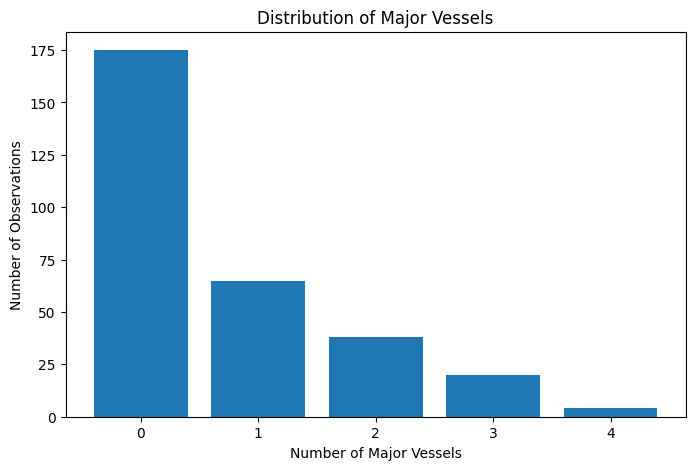

In [28]:
ca_distribution = df['ca'].value_counts().sort_index()

print("Distribution of Major Vessels (ca):")
display(ca_distribution)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(ca_distribution.index.astype(str), ca_distribution.values)

plt.title('Distribution of Major Vessels')
plt.xlabel('Number of Major Vessels')
plt.ylabel('Number of Observations')

plt.show()

Medium Level****

Question 1

Correlation between Age and Cholesterol: 0.2072


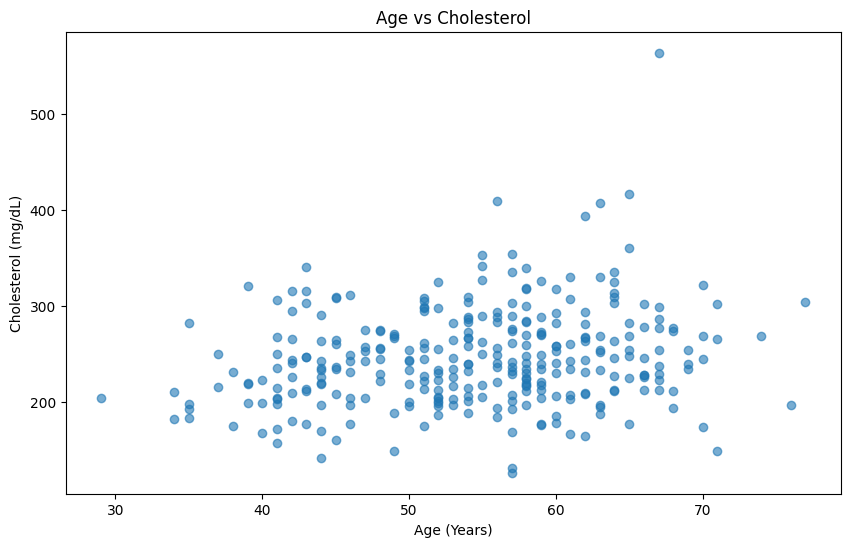

In [29]:
age_chol_correlation = df['age'].corr(df['chol'])

print(f"Correlation between Age and Cholesterol: {age_chol_correlation:.4f}")

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(df['age'], df['chol'], alpha=0.6)

plt.title('Age vs Cholesterol')
plt.xlabel('Age (Years)')
plt.ylabel('Cholesterol (mg/dL)')

plt.show()

Question 2

Chest Pain Distribution Across Age Groups:


cp,0,1,2,3
age_group,,,,
<40,4,3,6,2
40–49,28,19,22,3
50–59,61,21,34,9
60–69,46,4,21,9
70+,4,3,3,0


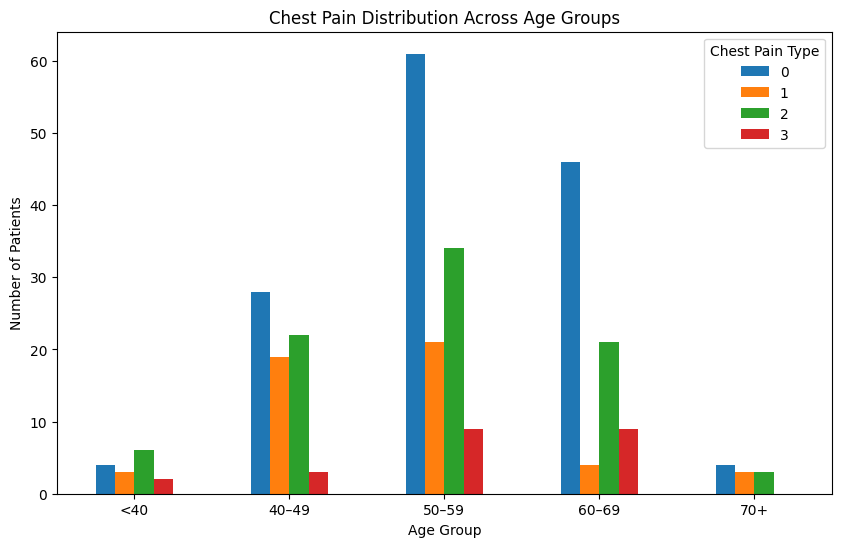

In [30]:
# Create age groups
age_bins = [0, 39, 49, 59, 69, 100]
age_labels = ['<40', '40–49', '50–59', '60–69', '70+']

df['age_group'] = pd.cut(
    df['age'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

cp_by_age_group = pd.crosstab(
    df['age_group'],
    df['cp']
)

print("Chest Pain Distribution Across Age Groups:")
display(cp_by_age_group)

# Visualize
import matplotlib.pyplot as plt

cp_by_age_group.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Chest Pain Distribution Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Chest Pain Type')
plt.show()

Question 3

Average Maximum Heart Rate by Exercise-Induced Angina:
No Angina (0): 155.60 bpm
Angina (1): 137.21 bpm


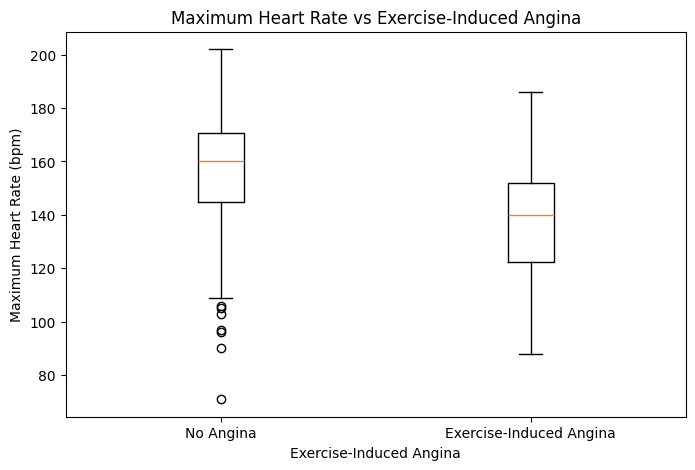

In [32]:
# Compare maximum heart rate for patients with and without exercise-induced angina
average_thalach_by_exang = (
    df.groupby('exang')['thalach']
    .mean()
)

print("Average Maximum Heart Rate by Exercise-Induced Angina:")
print(f"No Angina (0): {average_thalach_by_exang.get(0, 0):.2f} bpm")
print(f"Angina (1): {average_thalach_by_exang.get(1, 0):.2f} bpm")

# Visualize 
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df['exang'] == 0, 'thalach'],
        df.loc[df['exang'] == 1, 'thalach']
    ],
    tick_labels=['No Angina', 'Exercise-Induced Angina']
)

plt.title('Maximum Heart Rate vs Exercise-Induced Angina')
plt.xlabel('Exercise-Induced Angina')
plt.ylabel('Maximum Heart Rate (bpm)')

plt.show()

Question 4

In [33]:
# Separate resting blood pressure by sex
female_bp = df.loc[df['sex'] == 0, 'trestbps']
male_bp = df.loc[df['sex'] == 1, 'trestbps']

# Calculate average resting blood pressure
female_mean = female_bp.mean()
male_mean = male_bp.mean()

print(f"Average resting BP - Female: {female_mean:.2f} mmHg")
print(f"Average resting BP - Male: {male_mean:.2f} mmHg")

# Perform independent two-sample t-test
from scipy.stats import ttest_ind

t_statistic, p_value = ttest_ind(
    female_bp,
    male_bp,
    equal_var=False
)

print(f"\nT-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

# Statistical interpretation
if p_value < 0.05:
    print("\nResult: There is a statistically significant difference in resting BP between males and females.")
else:
    print("\nResult: There is no statistically significant difference in resting BP between males and females.")

Average resting BP - Female: 133.08 mmHg
Average resting BP - Male: 130.91 mmHg

T-statistic: 0.9485
P-value: 0.3443

Result: There is no statistically significant difference in resting BP between males and females.


Question 5

Fasting Blood Sugar vs Heart Disease:


target,0,1
fbs,,
0,116,141
1,22,23



Heart Disease Percentage by Fasting Blood Sugar:


target,0,1
fbs,,
0,45.14,54.86
1,48.89,51.11


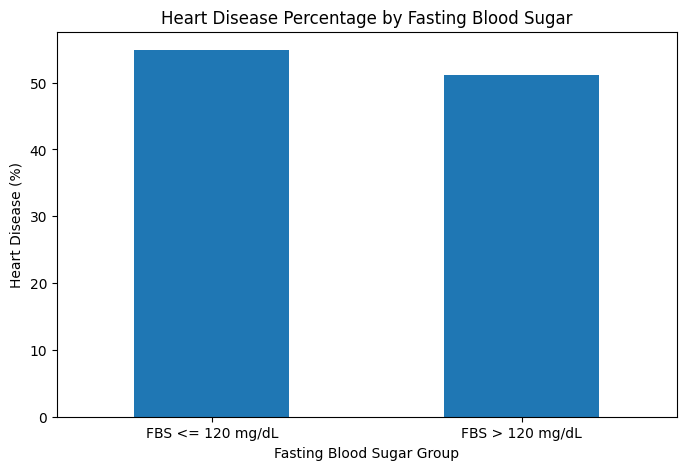

In [34]:
# Compare heart disease outcomes for patients with normal and high fasting blood sugar

fbs_target = pd.crosstab(
    df['fbs'],
    df['target']
)

print("Fasting Blood Sugar vs Heart Disease:")
display(fbs_target)

# Calculate heart disease percentage within each FBS group
fbs_target_percentage = pd.crosstab(
    df['fbs'],
    df['target'],
    normalize='index'
) * 100

print("\nHeart Disease Percentage by Fasting Blood Sugar:")
display(fbs_target_percentage.round(2))

# Rename categories for easier interpretation
fbs_target_percentage.index = [
    'FBS <= 120 mg/dL',
    'FBS > 120 mg/dL'
]

# Plot heart disease percentage
import matplotlib.pyplot as plt

fbs_target_percentage[1].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Heart Disease Percentage by Fasting Blood Sugar')
plt.xlabel('Fasting Blood Sugar Group')
plt.ylabel('Heart Disease (%)')
plt.xticks(rotation=0)
plt.show()

Question 6

Heart Disease Rate by Number of Major Vessels:


,count,heart_disease_percentage
ca,,
0,175,74.29
1,65,32.31
2,38,18.42
3,20,15.00
4,4,75.00


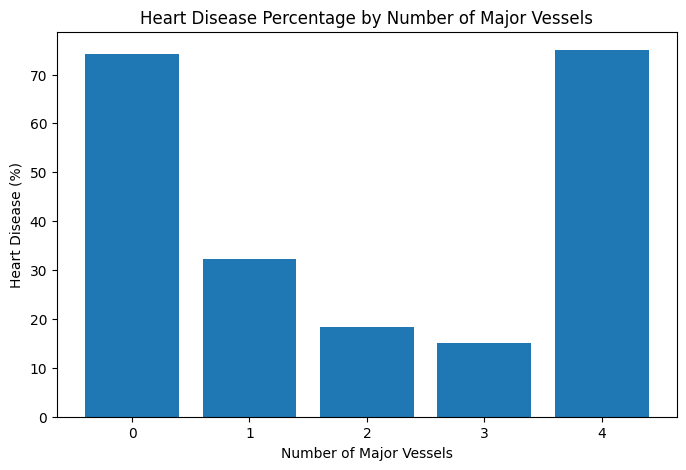

In [35]:
# Calculate heart disease rate for each number of major vessels
ca_target = (
    df.groupby('ca')['target']
    .agg(['count', 'mean'])
)

ca_target['heart_disease_percentage'] = ca_target['mean'] * 100

print("Heart Disease Rate by Number of Major Vessels:")
display(ca_target[['count', 'heart_disease_percentage']].round(2))

# Visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    ca_target.index.astype(str),
    ca_target['heart_disease_percentage']
)

plt.title('Heart Disease Percentage by Number of Major Vessels')
plt.xlabel('Number of Major Vessels')
plt.ylabel('Heart Disease (%)')

plt.show()

Question 7

Average Oldpeak by Chest Pain Type:


cp
0    1.38
1    0.32
2    0.81
3    1.39
Name: oldpeak, dtype: float64

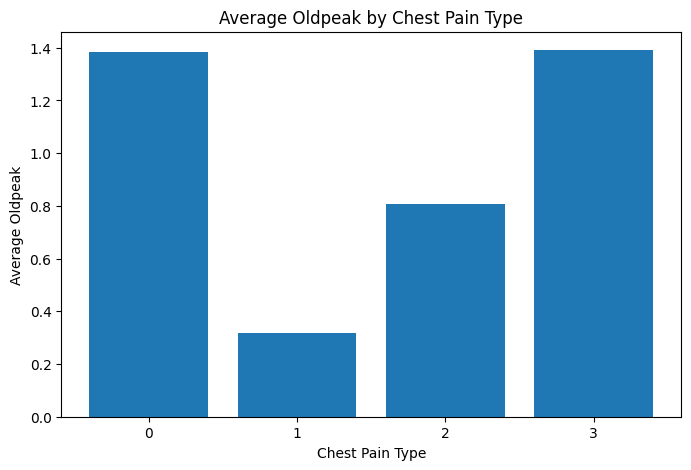

In [36]:
# Calculate average oldpeak for each chest pain type
average_oldpeak_by_cp = (
    df.groupby('cp')['oldpeak']
    .mean()
    .sort_index()
)

print("Average Oldpeak by Chest Pain Type:")
display(average_oldpeak_by_cp.round(2))

# Visualize 
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    average_oldpeak_by_cp.index.astype(str),
    average_oldpeak_by_cp.values
)

plt.title('Average Oldpeak by Chest Pain Type')
plt.xlabel('Chest Pain Type')
plt.ylabel('Average Oldpeak')

plt.show()

Question 8

Thalassemia Distribution Among Patients With Heart Disease:


thal
0      1
1      6
2    129
3     28
Name: count, dtype: int64


Thalassemia Distribution (%):


thal
0     0.61
1     3.66
2    78.66
3    17.07
Name: proportion, dtype: float64

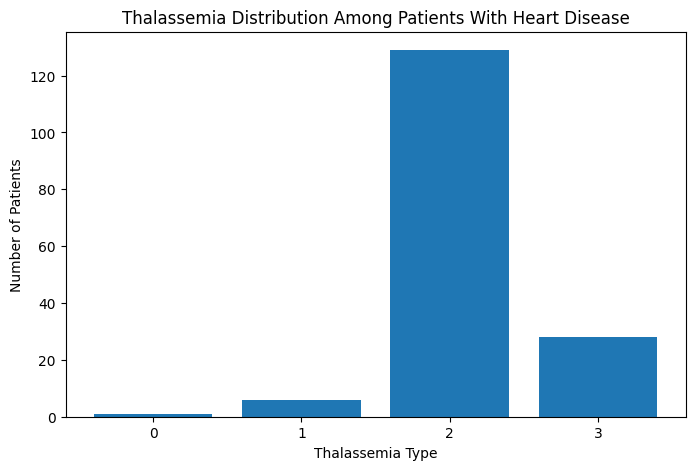

In [37]:
# Filter patients with heart disease
heart_disease_patients = df[df['target'] == 1]

# Count thalassemia types
thal_distribution = heart_disease_patients['thal'].value_counts().sort_index()

print("Thalassemia Distribution Among Patients With Heart Disease:")
display(thal_distribution)

# Calculate percentages
thal_percentage = (
    heart_disease_patients['thal']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nThalassemia Distribution (%):")
display(thal_percentage.round(2))

# Visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    thal_distribution.index.astype(str),
    thal_distribution.values
)

plt.title('Thalassemia Distribution Among Patients With Heart Disease')
plt.xlabel('Thalassemia Type')
plt.ylabel('Number of Patients')

plt.show()

Question 9

In [38]:
heart_disease_patients = df[df['target'] == 1].copy()

# Count combinations of CP, FBS, Exercise-Induced Angina and Thalassemia
common_combinations = (
    heart_disease_patients
    .groupby(['cp', 'fbs', 'exang', 'thal'])
    .size()
    .reset_index(name='Patient Count')
    .sort_values('Patient Count', ascending=False)
)

# Display the top 10 most common combinations
print("Top 10 Most Common Clinical Feature Combinations:")
display(common_combinations.head(10))

Top 10 Most Common Clinical Feature Combinations:


,cp,fbs,exang,thal,Patient Count
15,2,0,0,2,41
8,1,0,0,2,30
1,0,0,0,2,23
19,2,1,0,2,10
4,0,0,1,2,6
16,2,0,0,3,6
23,3,0,0,2,5
9,1,0,0,3,4
17,2,0,1,2,4
20,2,1,0,3,3


Question 10

Average Clinical Measurements by Heart Disease Status:


,No Heart Disease,Heart Disease
age,56.60,52.59
trestbps,134.40,129.25
chol,251.09,242.64
thalach,139.10,158.38
oldpeak,1.59,0.59



Difference in Average Measurements:


,No Heart Disease,Heart Disease,Difference
age,56.60,52.59,-4.02
trestbps,134.40,129.25,-5.15
chol,251.09,242.64,-8.45
thalach,139.10,158.38,19.28
oldpeak,1.59,0.59,-1.00


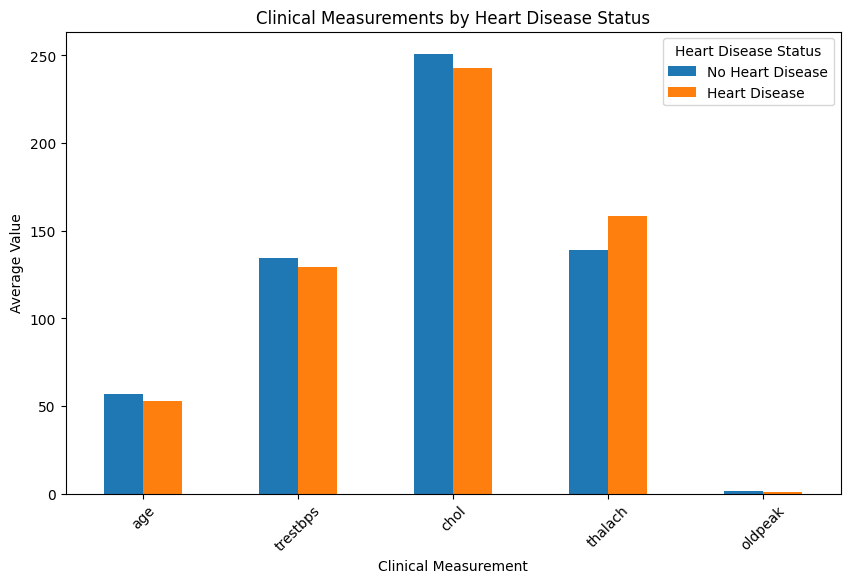

In [39]:
# Select important clinical measurements
clinical_columns = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

# Calculate mean values for patients with and without heart disease
clinical_comparison = (
    df.groupby('target')[clinical_columns]
    .mean()
    .T
)

# Rename columns for easier interpretation
clinical_comparison.columns = [
    'No Heart Disease',
    'Heart Disease'
]

print("Average Clinical Measurements by Heart Disease Status:")
display(clinical_comparison.round(2))

# Calculate the difference between the two groups
clinical_comparison['Difference'] = (
    clinical_comparison['Heart Disease']
    - clinical_comparison['No Heart Disease']
)

print("\nDifference in Average Measurements:")
display(clinical_comparison.round(2))

# Visualize the comparison
clinical_comparison[['No Heart Disease', 'Heart Disease']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Clinical Measurements by Heart Disease Status')
plt.xlabel('Clinical Measurement')
plt.ylabel('Average Value')
plt.xticks(rotation=45)
plt.legend(title='Heart Disease Status')
plt.show()

Advance Level****

Question 1

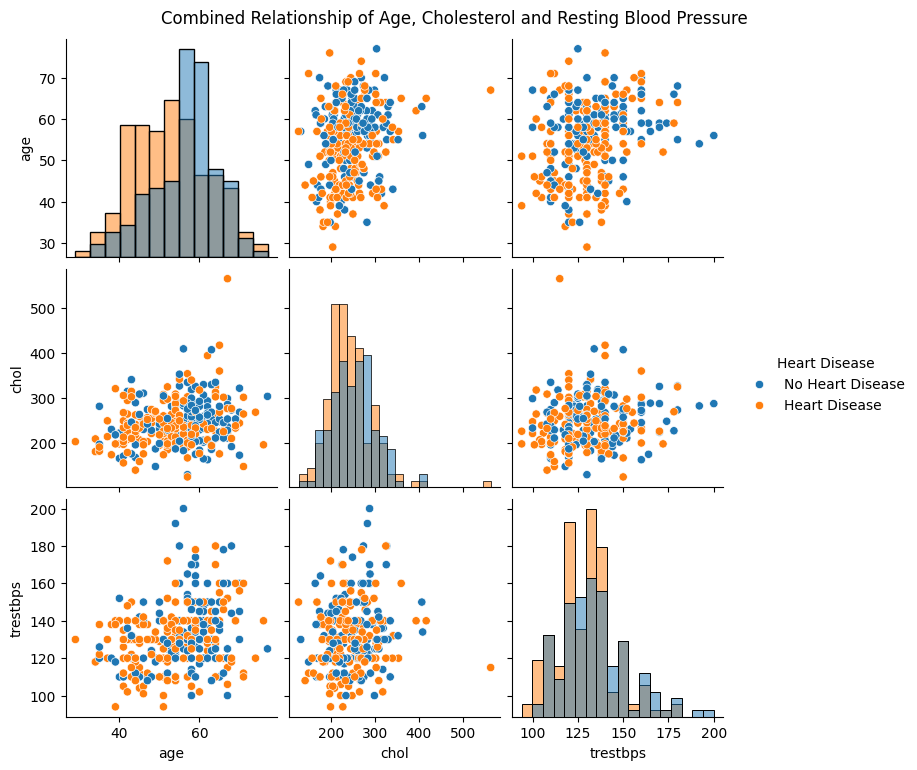

In [40]:
import seaborn as sns
# Select variables required for the analysis
pairplot_data = df[
    ['age', 'chol', 'trestbps', 'target']
].copy()

# Convert target into meaningful labels
pairplot_data['Heart Disease'] = pairplot_data['target'].map({
    0: 'No Heart Disease',
    1: 'Heart Disease'
})

# Create pairplot
sns.pairplot(
    pairplot_data,
    vars=['age', 'chol', 'trestbps'],
    hue='Heart Disease',
    diag_kind='hist',
    height=2.5
)

plt.suptitle(
    'Combined Relationship of Age, Cholesterol and Resting Blood Pressure',
    y=1.02
)

plt.show()

Question 2

Correlation of Clinical Measurements with Heart Disease:


oldpeak    -0.4291
thalach     0.4200
ca         -0.4090
age        -0.2215
trestbps   -0.1463
chol       -0.0814
Name: target, dtype: float64


Strongest correlation with heart disease: oldpeak
Correlation coefficient: -0.4291


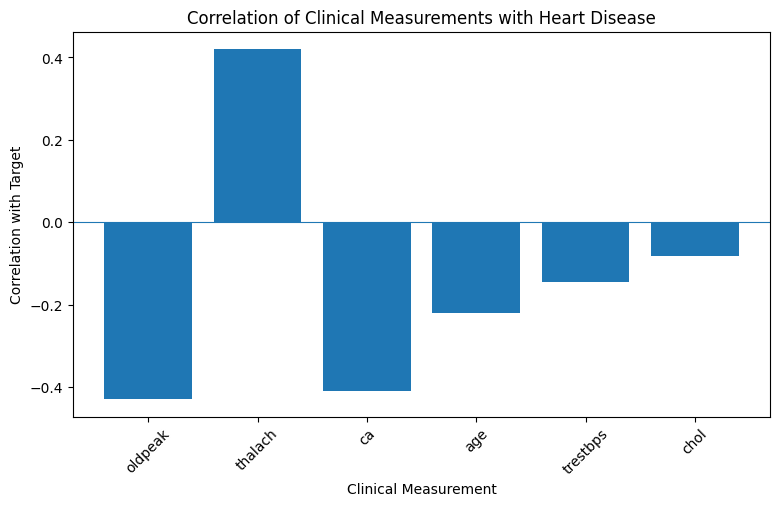

In [41]:
# Select clinical measurements and the target
clinical_variables = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak',
    'ca'
]

# Calculate correlation with heart disease outcome
correlations = (
    df[clinical_variables + ['target']]
    .corr()['target']
    .drop('target')
    .sort_values(key=abs, ascending=False)
)

print("Correlation of Clinical Measurements with Heart Disease:")
display(correlations.round(4))

# Identify the strongest correlation
strongest_variable = correlations.index[0]
strongest_correlation = correlations.iloc[0]

print(
    f"\nStrongest correlation with heart disease: "
    f"{strongest_variable}"
)
print(f"Correlation coefficient: {strongest_correlation:.4f}")

# Visualize 
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    correlations.index,
    correlations.values
)

plt.axhline(0, linewidth=0.8)

plt.title('Correlation of Clinical Measurements with Heart Disease')
plt.xlabel('Clinical Measurement')
plt.ylabel('Correlation with Target')
plt.xticks(rotation=45)

plt.show()

Question 3

Model Accuracy: 0.8361
ROC-AUC Score: 0.9048

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        28
           1       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61


Confusion Matrix:
[[23  5]
 [ 5 28]]


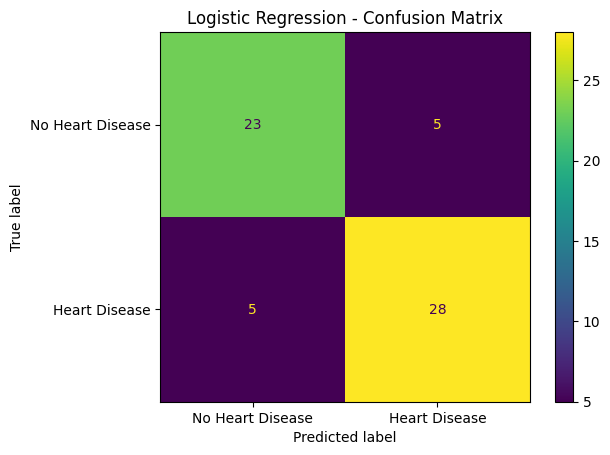

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

# Define features and target
features = [
    'age',
    'sex',
    'cp',
    'trestbps',
    'chol',
    'fbs',
    'restecg',
    'thalach',
    'exang',
    'oldpeak',
    'slope',
    'ca',
    'thal'
]

X = df[features]
y = df['target']

# Treat coded categorical variables as categorical
categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

numerical_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred = logistic_model.predict(X_test)
y_probability = logistic_model.predict_proba(X_test)[:, 1]

# Model evaluation
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Display confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Heart Disease', 'Heart Disease']
).plot()

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

Question 4

Distribution of Exercise Slope Across Chest Pain Types:


slope,0,1,2
cp,,,
0,11,84,48
1,2,12,36
2,5,33,48
3,3,11,9



Exercise Slope Distribution (%) Within Each Chest Pain Type:


slope,0,1,2
cp,,,
0,7.69,58.74,33.57
1,4.00,24.00,72.00
2,5.81,38.37,55.81
3,13.04,47.83,39.13


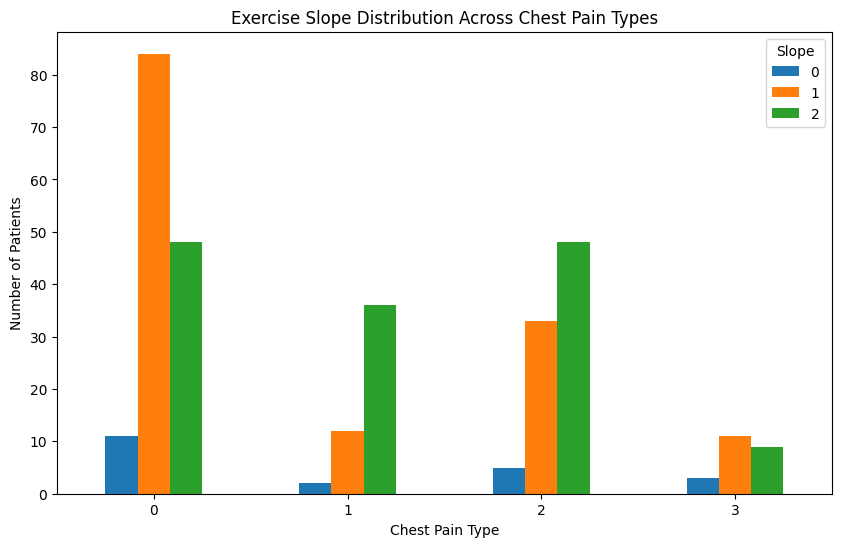

In [43]:
slope_cp_distribution = pd.crosstab(
    df['cp'],
    df['slope']
)

print("Distribution of Exercise Slope Across Chest Pain Types:")
display(slope_cp_distribution)

# Convert counts into percentages within each chest pain type
slope_cp_percentage = pd.crosstab(
    df['cp'],
    df['slope'],
    normalize='index'
) * 100

print("\nExercise Slope Distribution (%) Within Each Chest Pain Type:")
display(slope_cp_percentage.round(2))

# Visualize 
import matplotlib.pyplot as plt

slope_cp_distribution.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Exercise Slope Distribution Across Chest Pain Types')
plt.xlabel('Chest Pain Type')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.legend(title='Slope')
plt.show()

Question 5

Thalassemia Type vs Heart Disease Outcome:


target,0,1
thal,,
0,1,1
1,12,6
2,36,129
3,89,28



Heart Disease Outcome (%) Within Each Thalassemia Type:


target,0,1
thal,,
0,50.00,50.00
1,66.67,33.33
2,21.82,78.18
3,76.07,23.93


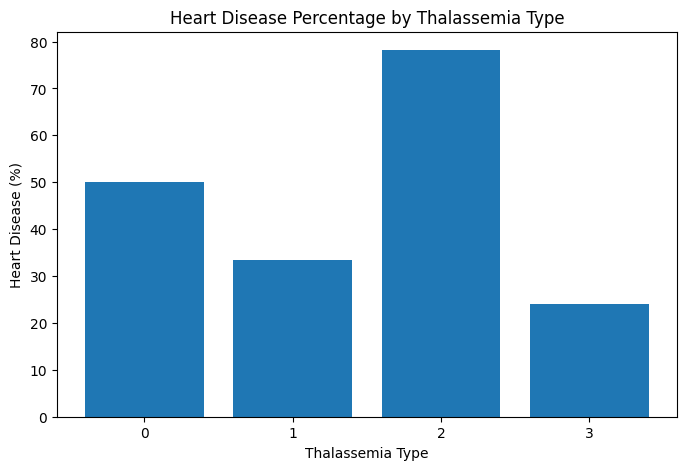

In [44]:
thal_target = pd.crosstab(
    df['thal'],
    df['target']
)

print("Thalassemia Type vs Heart Disease Outcome:")
display(thal_target)

# Calculate percentage of heart disease cases within each thalassemia group
thal_target_percentage = pd.crosstab(
    df['thal'],
    df['target'],
    normalize='index'
) * 100

print("\nHeart Disease Outcome (%) Within Each Thalassemia Type:")
display(thal_target_percentage.round(2))

# Visualize heart disease percentage by thalassemia type
import matplotlib.pyplot as plt

heart_disease_percentage = thal_target_percentage[1]

plt.figure(figsize=(8, 5))

plt.bar(
    heart_disease_percentage.index.astype(str),
    heart_disease_percentage.values
)

plt.title('Heart Disease Percentage by Thalassemia Type')
plt.xlabel('Thalassemia Type')
plt.ylabel('Heart Disease (%)')

plt.show()